# Refining the expanded Random Forest

The expanded RF still predicts too close to the middle of the pressure range. We tested four focused changes: deeper shared trees, separate forests for the two pressures, equal-group training weights on the reference model, and equal-group weights on separate deeper forests.

The 60 features, 1,308 training recordings, quality rules, labels and grouped folds stay fixed. Selection uses training OOF predictions only. A replacement must improve mean target/group MAE by at least 0.05 mmHg without worsening either target. Only the chosen replacement and reference are scored on exploratory validation. The old test is not accessed.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
RUN=Path('outputs/rf_refinement_oct28')
decision=json.loads((RUN/'selection.json').read_text())
print('Training-selected candidate:', decision['selected'])
metrics=pd.read_csv(RUN/'training_oof_metrics.csv')
display(metrics.pivot(index='model',columns='target',values=['mae_mmHg','overlap_group_macro_mae']).round(3))

Training-selected candidate: Deeper joint RF


mae_mmHg         overlap_group_macro_mae        
target                           dbp     sbp                     dbp     sbp
model                                                                       
Deeper joint RF                7.286  14.868                   7.435  14.936
Expanded reference RF          7.431  15.285                   7.557  15.310
Group-balanced reference RF    7.415  15.350                   7.539  15.379
Group-balanced separate RF     7.272  14.903                   7.411  14.965
Separate-target RF             7.333  14.859                   7.470  14.915

## Check validation after selecting

These are the same 857 validation windows used earlier, so the results are development evidence rather than a new final score. Lower MAE and RMSE are better. The paired intervals give each overlap group equal weight and do not account for all repeated model-development decisions.

In [2]:
validation=pd.read_csv(RUN/'validation_metrics.csv')
display(validation.pivot(index='model',columns='target',values=['mae_mmHg','rmse_mmHg']).round(3))
display(pd.read_csv(RUN/'validation_paired_group_gains.csv').round(3))

mae_mmHg         rmse_mmHg        
target                     dbp     sbp       dbp     sbp
model                                                   
Deeper joint RF          8.343  15.764    11.442  21.227
Expanded reference RF    8.552  16.117    11.649  21.490

,target,equal_group_mae_gain,ci_low,ci_high
0,sbp,0.196,-0.253,0.616
1,dbp,0.234,0.047,0.445


## Are extreme pressures still difficult?

Each point represents one training pressure quarter, using out-of-fold predictions. A good fit would stay near the diagonal. Predictions that cluster near the middle still miss low and high pressures, even if overall MAE improves.

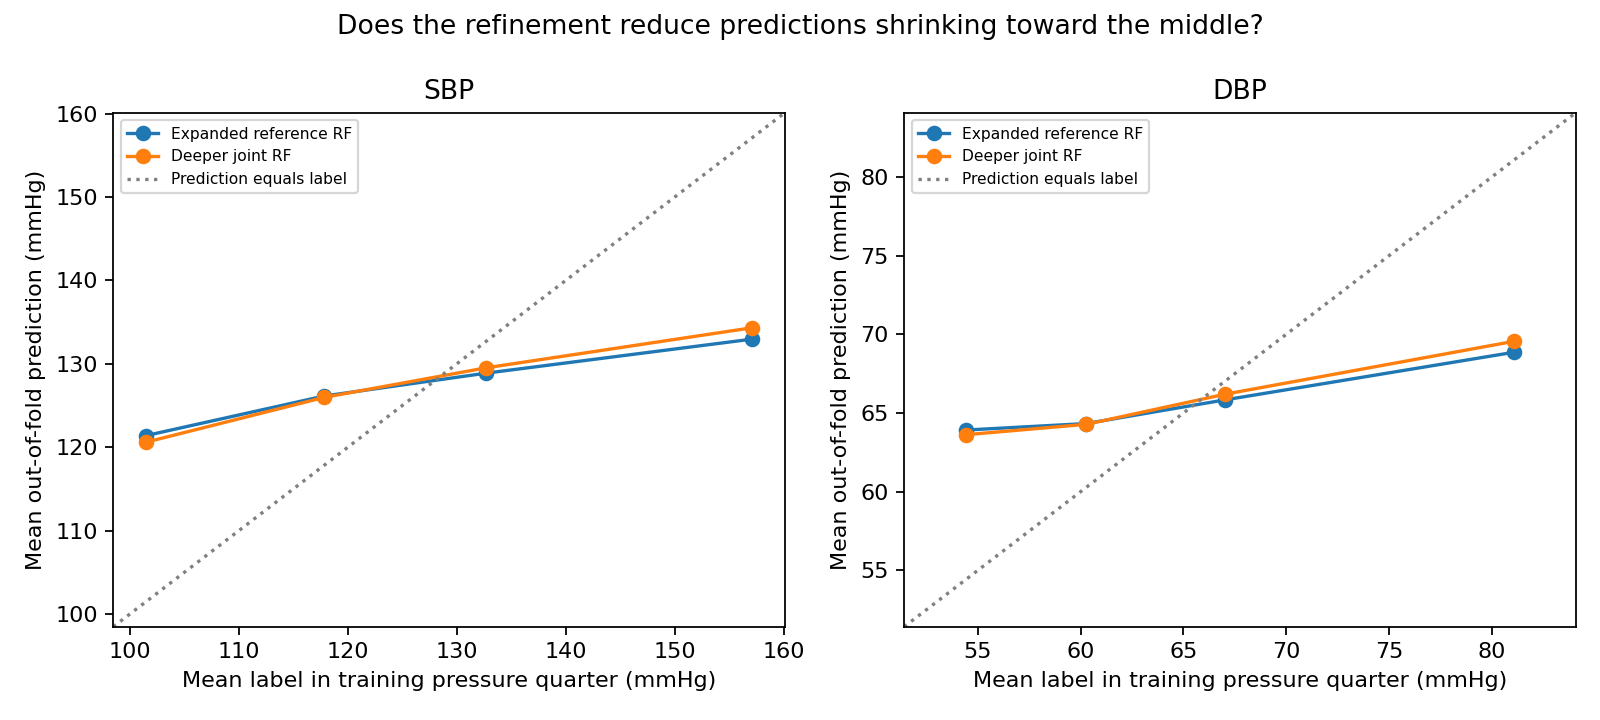

,model,target,quartile,windows,label_mean,prediction_mean,mae,bias
0,Deeper joint RF,sbp,1,2823,101.50,120.62,19.46,19.12
1,Deeper joint RF,sbp,2,2823,117.84,125.98,9.66,8.14
2,Deeper joint RF,sbp,3,2824,132.68,129.53,7.29,-3.15
3,Deeper joint RF,sbp,4,2821,157.13,134.34,23.07,-22.79
4,Expanded reference RF,sbp,1,2823,101.50,121.40,20.16,19.91
5,Expanded reference RF,sbp,2,2823,117.84,126.15,9.42,8.31
6,Expanded reference RF,sbp,3,2824,132.68,128.89,7.18,-3.79
7,Expanded reference RF,sbp,4,2821,157.13,132.98,24.39,-24.16
20,Deeper joint RF,dbp,1,2826,54.41,63.62,9.21,9.21
21,Deeper joint RF,dbp,2,2824,60.28,64.28,4.56,4.01


In [3]:
display(Image(filename=str(RUN/'training_shrinkage.png')))
bands=pd.read_csv(RUN/'training_pressure_quartile_errors.csv')
display(bands[bands.model.isin(['Expanded reference RF',decision['selected']])].round(2))

## Use the trained model on PPG

`predict_ppg_rf.py` takes a one-dimensional NumPy PPG recording at 125 Hz and a start sample. It extracts the same original and complete-pulse features, then loads an explicitly specified saved model. The requested five-second window needs at least one second of recording context on each side. PPG checks are applied; ABP-based label checks are unavailable at inference.

The raw-PPG prediction was checked against the saved-feature prediction on a training example. Model binaries stay local and must be regenerated before using an uploaded copy. These remain research predictions with provisional pressure labels and no confirmed patient-level evaluation. See [the full report](RF_REFINEMENT_RESULTS.md).

In [4]:
display(pd.read_json(RUN/'inference_check.json',typ='series'))

window_key                             Part_1:0032:0001
split                                             train
model                                selected_rf.joblib
prediction_matches_saved_features                  True
dtype: object

## Reproduce

`refine_expanded_rf.py --output-dir outputs/rf_refinement_new_run` reruns the experiment using the saved feature tables and earlier reference checkpoint. `summarize_rf_refinement.py` regenerates the report and diagnostics. Run `python -m unittest test_refine_expanded_rf test_predict_ppg_rf -v` for the weighting and inference-input checks.